# Evaluación de modelos BCS (fase de Evaluation de CRISP-DM)

El objetivo de esta libreta es medir, con métricas y pruebas estadísticas, si los modelos cumplen los criterios de éxito definidos en Business Understanding, y revisar cómo se comportan.

Marco de evaluación acordado con el profesor:
- El benchmark es una partición única train/val/test por animal (`grouped_holdout`, semilla 42; 402/102/100 fotos y 51/13/16 animales). Train ajusta los modelos, val elige hiperparámetros y test se usa una sola vez.
- La validación cruzada de 5 folds por animal solo sirve para validar (estabilidad, sobreajuste y si el ranking se mantiene). No se usa para elegir el modelo final.
- Solo se usan fotos del rancho (CAETEC), ningún dato de ScienceDB.

La libreta lee predicciones ya calculadas que están fuera del repositorio (`~/bcs_data/`, porque son confidenciales). Lo que se muestra aquí son solo agregados, sin fotos ni identificadores de vacas.

Contenido:
1. Carga y verificación de fugas
2. Métricas y criterios
3. Benchmark en test
4. Pruebas estadísticas
5. Diagnósticos
6. Validación cruzada
7. Ablación
8. Resumen

In [1]:
import re, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import cohen_kappa_score
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

RAIZ = Path.home() / 'bcs_data'          # datos confidenciales, fuera del repo
FIG = RAIZ / 'eval' / 'figs'; FIG.mkdir(parents=True, exist_ok=True)
SEMILLA, B = 42, 5000
RANGO = (3.25, 3.50)                      # intervalo del criterio original
CRITERIOS = {'MAE': 0.25, 'RMSE': 0.35, 'tol': 80.0}

# Modelos del benchmark (columna -> etiqueta). YOLO sin imágenes externas.
PRINCIPAL = 'ridge_dinov2_l_mascara_clahe_cls_parches_448'
MODELOS = {
    'E0_constante': 'E0 · constante',
    'ridge_resnet50_mascara_clahe_final_224': 'ResNet-50 + Ridge',
    'E1_cnn_afinada': 'E1 · ResNet-50 afinada',
    'YOLO_caja_sin_ext_base_top1': 'YOLO26s-cls base (caja)',
    'YOLO_caja_sin_ext_dropout_top1': 'YOLO26s-cls dropout (caja)',
    'YOLO_classifier_baseline_prob': 'YOLO26s-cls base (SAM)',
    'E4_mlp_dinov2_l_mascara_clahe_cls_parches_448': 'DINOv2-L + MLP',
    'ridge_caja_dinov2_l_448_cls_parches': 'DINOv2-L + Ridge (caja)',
    PRINCIPAL: 'DINOv2-L + Ridge (SAM+CLAHE)',
}
# mismo modelo en los archivos de folds
EN_FOLDS = {'YOLO_classifier_baseline_prob': 'YOLO_sam_base_prob',
            'E4_mlp_dinov2_l_mascara_clahe_cls_parches_448': 'mlp_dinov2_l_mascara_clahe_cls_parches_448'}
COLOR = {c: '#9aa5b1' for c in MODELOS}
COLOR.update({'E0_constante': '#5b6770', 'ridge_caja_dinov2_l_448_cls_parches': '#7fb2e5', PRINCIPAL: '#1f6fc5'})
for c in ['YOLO_caja_sin_ext_base_top1', 'YOLO_caja_sin_ext_dropout_top1', 'YOLO_classifier_baseline_prob']:
    COLOR[c] = '#e0a458'

redondear = lambda x: np.clip(np.round(np.asarray(x, float) * 4) / 4, 1, 5)

def metricas(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = p - y
    return {'MAE': np.abs(e).mean(), 'RMSE': np.sqrt((e ** 2).mean()),
            'tol': 100 * np.mean(np.abs(redondear(p) - y) <= 0.25 + 1e-9),
            'kappa_w': cohen_kappa_score((y * 4).astype(int), (redondear(p) * 4).astype(int), weights='quadratic'),
            'spearman': stats.spearmanr(y, p).correlation, 'sesgo': e.mean(), 'n': len(y)}

def por_vaca(df, cols):
    # una fila por sesión de vaca (id_vaca): promedio de sus fotos
    return df.groupby('id_vaca').agg(animal=('animal', 'first'), bcs=('bcs', 'first'), **{c: (c, 'mean') for c in cols}).reset_index()

def cumple(m):
    return m['MAE'] <= CRITERIOS['MAE'] and m['RMSE'] <= CRITERIOS['RMSE'] and m['tol'] >= CRITERIOS['tol']

## 1. Carga de predicciones y verificación de fugas

Cada modelo se entrenó solo con train; val eligió los hiperparámetros (alpha de Ridge y parada temprana de YOLO y E1) y test se evaluó una sola vez. Antes de medir revisamos que ningún animal ni ninguna imagen idéntica (SHA-256 del contenido) aparezca en más de una partición.

In [2]:
H = RAIZ / 'holdout'
p = pd.read_csv(H / 'pred_caja_yolo.csv', dtype={'id_vaca': str, 'animal': str})
for f in ['pred_holdout.csv', 'pred_yolo.csv', 'pred_caja_dino.csv']:
    q = pd.read_csv(H / f)
    p = p.merge(q.drop(columns=[c for c in q.columns if c in p.columns and c != 'archivo_limpio']), on='archivo_limpio', validate='1:1')
p = p[['archivo_limpio', 'id_vaca', 'animal', 'bcs', 'split'] + [c for c in p.columns if c not in {'archivo_limpio', 'id_vaca', 'animal', 'bcs', 'split'}]]
assert len(p) == 604 and p[list(MODELOS)].notna().all().all()

# fugas: animales y contenido idéntico entre particiones
assert p.groupby('animal')['split'].nunique().max() == 1, 'un animal aparece en dos particiones'
img = pd.read_csv(RAIZ / 'imagenes.csv', usecols=['archivo_limpio', 'hash'])
img['archivo_limpio'] = img['archivo_limpio'].str.extract(r'(clean/.+)$')[0]
h = p.merge(img.drop_duplicates('archivo_limpio'), on='archivo_limpio', how='left')
assert h['hash'].notna().all()
cruces = h.groupby('hash')['split'].nunique().gt(1).sum()
print(f'Hashes compartidos entre particiones: {cruces}')
assert cruces == 0

comp = p.groupby('split').agg(fotos=('bcs', 'size'), animales=('animal', 'nunique'), sesiones=('id_vaca', 'nunique'), bcs_medio=('bcs', 'mean'))
comp.loc[['train', 'val', 'test']].round(2)

Hashes compartidos entre particiones: 0


,fotos,animales,sesiones,bcs_medio
split,,,,
train,402,51,59,3.00
val,102,13,15,3.05
test,100,16,19,3.04


In [3]:
# distribución de BCS por partición (fotos)
pd.crosstab(p['bcs'], p['split'])[['train', 'val', 'test']]

split,train,val,test
bcs,,,
2.00,4,0,0
2.25,2,4,0
2.50,70,14,13
2.75,96,18,28
3.00,85,24,20
3.25,67,16,17
3.50,38,16,11
3.75,40,10,11


## 2. Métricas e indicadores

| Indicador | Por qué lo usamos |
|---|---|
| MAE (error absoluto medio) | Es el error típico en puntos BCS y el veterinario lo puede interpretar directamente. Es la métrica objetivo de Business Understanding. |
| RMSE | Penaliza más los errores grandes; clasificar una vaca flaca como normal es más grave que equivocarse por 0.25. |
| Acierto tolerado ±0.25 | La predicción redondeada al paso de 0.25 queda a un paso o menos del experto. Es la tolerancia usual en la literatura de BCS por imagen, porque la escala va de 0.25 en 0.25 y dos evaluadores humanos suelen diferir en un paso. |
| κ ponderado cuadrático | Mide la concordancia con el experto corrigiendo por azar y castiga más los desacuerdos lejanos (la escala es ordinal). |
| Spearman | Indica si el modelo ordena bien a las vacas de más flaca a más gorda. |
| Sesgo (media de predicho menos real) | Sirve para detectar regresión a la media. |

Reportamos todo por foto (como lo pide el criterio) y por vaca (promedio de las fotos de una sesión, que es la unidad que usa la granja).

Criterios de éxito de Business Understanding: MAE ≤ 0.25, RMSE ≤ 0.35 y al menos 80 % dentro de ±0.25, medidos originalmente solo en fotos con BCS real entre 3.25 y 3.50. Ese intervalo se eligió cuando se planeaba entrenar con ScienceDB (clases 3.25 y 3.50); el cambio se explica en el apéndice de enmienda del reporte.

## 3. Benchmark: resultados en test (100 fotos de 16 animales)

In [4]:
te = p[p['split'] == 'test']
tv = por_vaca(te, list(MODELOS))
filas = []
for c, n in MODELOS.items():
    mf, mv = metricas(te['bcs'], te[c]), metricas(tv['bcs'], tv[c])
    filas.append({'modelo': n, 'MAE': mf['MAE'], 'RMSE': mf['RMSE'], '±0.25 %': mf['tol'], 'κ_w': mf['kappa_w'],
                  'Spearman': mf['spearman'], 'sesgo': mf['sesgo'],
                  'MAE vaca': mv['MAE'], 'RMSE vaca': mv['RMSE'], '±0.25 % vaca': mv['tol']})
bench = pd.DataFrame(filas).sort_values('MAE').reset_index(drop=True)
bench.to_csv(RAIZ / 'eval' / 'benchmark_test.csv', index=False)
bench.round(3)

,modelo,MAE,RMSE,±0.25 %,κ_w,Spearman,sesgo,MAE vaca,RMSE vaca,±0.25 % vaca
0,DINOv2-L + Ridge (SAM+CLAHE),0.210,0.265,81.0,0.676,0.734,-0.106,0.186,0.231,89.474
1,DINOv2-L + Ridge (caja),0.227,0.272,84.0,0.683,0.757,-0.124,0.206,0.250,89.474
2,DINOv2-L + MLP,0.282,0.339,67.0,0.346,0.579,-0.107,0.264,0.322,68.421
3,ResNet-50 + Ridge,0.293,0.361,68.0,0.449,0.482,-0.135,0.276,0.351,63.158
4,E0 · constante,0.320,0.392,65.0,0.000,NaN,-0.075,0.297,0.377,68.421
5,YOLO26s-cls base (SAM),0.325,0.420,60.0,0.287,0.441,-0.226,0.298,0.377,63.158
6,E1 · ResNet-50 afinada,0.325,0.391,65.0,0.359,0.272,-0.142,0.279,0.350,68.421
7,YOLO26s-cls dropout (caja),0.328,0.419,61.0,0.298,0.354,-0.178,0.261,0.350,73.684
8,YOLO26s-cls base (caja),0.360,0.447,54.0,0.153,0.149,-0.170,0.301,0.379,73.684


### 3.1 Criterios de éxito: original (3.25 a 3.50) y ajustado (rango completo)

In [5]:
filas = []
for c in [PRINCIPAL, 'ridge_caja_dinov2_l_448_cls_parches', 'YOLO_caja_sin_ext_dropout_top1', 'YOLO_caja_sin_ext_base_top1', 'E1_cnn_afinada', 'E0_constante']:
    for nivel, df in [('foto', te), ('vaca', tv)]:
        for nombre, sub in [('original 3.25–3.50', df[df['bcs'].between(*RANGO)]), ('ajustado: rango completo', df)]:
            m = metricas(sub['bcs'], sub[c])
            filas.append({'modelo': MODELOS[c], 'criterio': nombre, 'nivel': nivel, 'n': m['n'], 'MAE': m['MAE'], 'RMSE': m['RMSE'],
                          '±0.25 %': m['tol'], 'MAE≤0.25': m['MAE'] <= 0.25, 'RMSE≤0.35': m['RMSE'] <= 0.35, '≥80 %': m['tol'] >= 80, 'cumple': cumple(m)})
crit = pd.DataFrame(filas)
crit.to_csv(RAIZ / 'eval' / 'criterios_test.csv', index=False)
print(f"Test en el intervalo 3.25–3.50: {te['bcs'].between(*RANGO).sum()} fotos de {te.loc[te['bcs'].between(*RANGO), 'animal'].nunique()} animales")
crit.round(3)

Test en el intervalo 3.25–3.50: 28 fotos de 4 animales


,modelo,criterio,nivel,n,MAE,RMSE,±0.25 %,MAE≤0.25,RMSE≤0.35,≥80 %,cumple
0,DINOv2-L + Ridge (SAM+CLAHE),original 3.25–3.50,foto,28,0.348,0.374,57.143,False,False,False,False
1,DINOv2-L + Ridge (SAM+CLAHE),ajustado: rango completo,foto,100,0.210,0.265,81.000,True,True,True,True
2,DINOv2-L + Ridge (SAM+CLAHE),original 3.25–3.50,vaca,5,0.320,0.327,80.000,False,True,True,False
3,DINOv2-L + Ridge (SAM+CLAHE),ajustado: rango completo,vaca,19,0.186,0.231,89.474,True,True,True,True
4,DINOv2-L + Ridge (caja),original 3.25–3.50,foto,28,0.322,0.344,75.000,False,True,False,False
5,DINOv2-L + Ridge (caja),ajustado: rango completo,foto,100,0.227,0.272,84.000,True,True,True,True
6,DINOv2-L + Ridge (caja),original 3.25–3.50,vaca,5,0.282,0.296,80.000,False,True,True,False
7,DINOv2-L + Ridge (caja),ajustado: rango completo,vaca,19,0.206,0.250,89.474,True,True,True,True
8,YOLO26s-cls dropout (caja),original 3.25–3.50,foto,28,0.473,0.524,32.143,False,False,False,False
9,YOLO26s-cls dropout (caja),ajustado: rango completo,foto,100,0.328,0.419,61.000,False,False,False,False


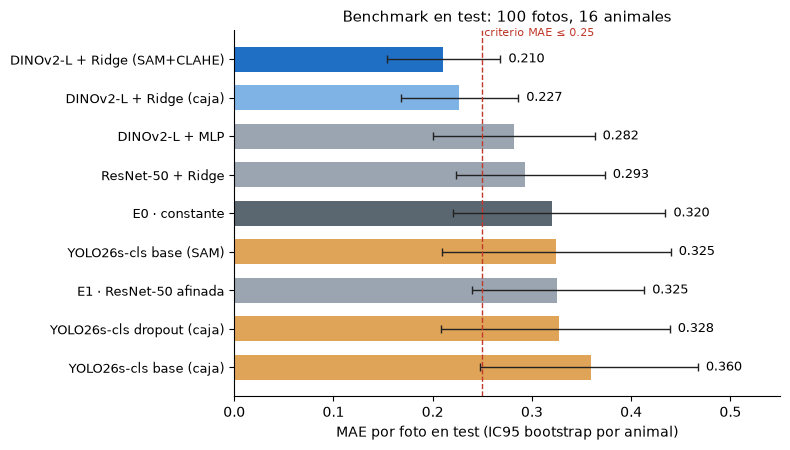

In [6]:
# Figura 1: MAE por foto en test con IC95 bootstrap por animal
def boot_mae(df, c, semilla=SEMILLA):
    g = df.assign(e=(df[c] - df['bcs']).abs(), n=1).groupby('animal')[['e', 'n']].sum().to_numpy()
    idx = np.random.default_rng(semilla).integers(0, len(g), size=(B, len(g)))
    return np.percentile(g[idx, 0].sum(1) / g[idx, 1].sum(1), [2.5, 97.5])

orden = bench['modelo'].tolist()[::-1]
inv = {v: k for k, v in MODELOS.items()}
fig, ax = plt.subplots(figsize=(8, 4.6))
for i, n in enumerate(orden):
    c = inv[n]; m = np.abs(te[c] - te['bcs']).mean(); lo, hi = boot_mae(te, c)
    ax.barh(i, m, color=COLOR[c], height=0.65)
    ax.errorbar(m, i, xerr=[[m - lo], [hi - m]], color='#222', capsize=3, lw=1)
    ax.text(hi + 0.008, i, f'{m:.3f}', va='center', fontsize=9)
ax.axvline(0.25, color='#c0392b', ls='--', lw=1); ax.text(0.252, len(orden) - 0.4, 'criterio MAE ≤ 0.25', color='#c0392b', fontsize=8)
ax.set_yticks(range(len(orden))); ax.set_yticklabels(orden, fontsize=9)
ax.set_xlabel('MAE por foto en test (IC95 bootstrap por animal)'); ax.set_xlim(0, 0.55)
ax.spines[['top', 'right']].set_visible(False); ax.set_title('Benchmark en test: 100 fotos, 16 animales', fontsize=11)
plt.tight_layout(); plt.savefig(FIG / 'fig1_benchmark_mae.png', dpi=200); plt.show()

## 4. Pruebas estadísticas

En test hay 16 animales y las fotos de una misma vaca no son independientes, por eso remuestreamos por animal:

1. Bootstrap pareado por animal (5000 réplicas): intervalo de confianza del 95 % para la diferencia de MAE entre dos modelos sobre las mismas fotos (Efron & Tibshirani, 1993).
2. Prueba de rangos con signo de Wilcoxon sobre el MAE por animal: es la prueba no paramétrica que se recomienda para comparar modelos sin suponer normalidad (Demšar, 2006).
3. Corrección de Holm por comparaciones múltiples (Holm, 1979).
4. Prueba de permutación (Ojala & Garriga, 2010): barajamos las etiquetas entre vacas en train y val, volvemos a entrenar Ridge y medimos el MAE en test. Si el modelo solo aprendiera ruido, su MAE real no se distinguiría de los obtenidos con etiquetas barajadas.

In [7]:
def mae_animal(df, c):
    return df.assign(e=(df[c] - df['bcs']).abs()).groupby('animal')['e'].mean()

def comparar(df, a, b, semilla=SEMILLA):
    # diferencia MAE(b) - MAE(a) por foto; >0 significa que a es mejor
    g = df.assign(ea=(df[a] - df['bcs']).abs(), eb=(df[b] - df['bcs']).abs(), n=1).groupby('animal')[['ea', 'eb', 'n']].sum().to_numpy()
    idx = np.random.default_rng(semilla).integers(0, len(g), size=(B, len(g)))
    d = (g[idx, 1].sum(1) - g[idx, 0].sum(1)) / g[idx, 2].sum(1)
    w = stats.wilcoxon(mae_animal(df, b), mae_animal(df, a))
    return (g[:, 1].sum() - g[:, 0].sum()) / g[:, 2].sum(), *np.percentile(d, [2.5, 97.5]), w.pvalue

def holm(pv):
    pv = np.asarray(pv); o = np.argsort(pv); adj = np.empty_like(pv)
    adj[o] = np.minimum(1, np.maximum.accumulate((len(pv) - np.arange(len(pv))) * pv[o]))
    return adj

def tabla_pruebas(df, pares):
    t = pd.DataFrame([dict(zip(['comparación', 'ΔMAE', 'IC95 bajo', 'IC95 alto', 'p Wilcoxon'], [f'{MODELOS[a]} vs {MODELOS[b]}', *comparar(df, a, b)])) for a, b in pares])
    t['p Holm'] = holm(t['p Wilcoxon']); t['IC excluye 0'] = t['IC95 bajo'] > 0
    return t

otros = [c for c in MODELOS if c not in ('E0_constante', PRINCIPAL)]
print('A) ¿Cada modelo supera a la referencia E0? (ΔMAE > 0 = mejor que E0)')
pA = tabla_pruebas(te, [(c, 'E0_constante') for c in [PRINCIPAL] + otros])
display(pA.round(4))
print('B) ¿DINOv2-L + Ridge (SAM+CLAHE) supera a los demás? (ΔMAE > 0 = DINOv2 mejor)')
pB = tabla_pruebas(te, [(PRINCIPAL, c) for c in otros])
display(pB.round(4))
pd.concat([pA.assign(familia='vs E0'), pB.assign(familia='vs DINOv2')]).to_csv(RAIZ / 'eval' / 'pruebas_test.csv', index=False)

A) ¿Cada modelo supera a la referencia E0? (ΔMAE > 0 = mejor que E0)


,comparación,ΔMAE,IC95 bajo,IC95 alto,p Wilcoxon,p Holm,IC excluye 0
0,DINOv2-L + Ridge (SAM+CLAHE) vs E0 · constante,0.1100,0.0111,0.2234,0.0739,0.5913,True
1,ResNet-50 + Ridge vs E0 · constante,0.0269,-0.0567,0.1230,0.7436,1.0000,False
2,E1 · ResNet-50 afinada vs E0 · constante,-0.0047,-0.0975,0.1113,0.7057,1.0000,False
3,YOLO26s-cls base (caja) vs E0 · constante,-0.0397,-0.1248,0.0620,0.5672,1.0000,False
4,YOLO26s-cls dropout (caja) vs E0 · constante,-0.0072,-0.1010,0.1198,0.8356,1.0000,False
5,YOLO26s-cls base (SAM) vs E0 · constante,-0.0043,-0.1088,0.1172,0.9799,1.0000,False
6,DINOv2-L + MLP vs E0 · constante,0.0380,-0.0157,0.0982,0.1167,0.8167,False
7,DINOv2-L + Ridge (caja) vs E0 · constante,0.0936,-0.0029,0.2039,0.2312,1.0000,False


B) ¿DINOv2-L + Ridge (SAM+CLAHE) supera a los demás? (ΔMAE > 0 = DINOv2 mejor)


,comparación,ΔMAE,IC95 bajo,IC95 alto,p Wilcoxon,p Holm,IC excluye 0
0,DINOv2-L + Ridge (SAM+CLAHE) vs ResNet-50 + Ridge,0.0831,0.0259,0.1442,0.0076,0.0534,True
1,DINOv2-L + Ridge (SAM+CLAHE) vs E1 · ResNet-50...,0.1147,0.0415,0.1984,0.0182,0.1095,True
2,DINOv2-L + Ridge (SAM+CLAHE) vs YOLO26s-cls ba...,0.1497,0.0791,0.2223,0.0290,0.1450,True
3,DINOv2-L + Ridge (SAM+CLAHE) vs YOLO26s-cls dr...,0.1172,0.0356,0.1971,0.0577,0.1730,True
4,DINOv2-L + Ridge (SAM+CLAHE) vs YOLO26s-cls ba...,0.1143,0.0376,0.1981,0.0386,0.1545,True
5,DINOv2-L + Ridge (SAM+CLAHE) vs DINOv2-L + MLP,0.0720,0.0192,0.1320,0.0934,0.1869,True
6,DINOv2-L + Ridge (SAM+CLAHE) vs DINOv2-L + Rid...,0.0164,-0.0094,0.0459,0.1591,0.1869,False


MAE test real 0.210 · permutado: media 0.332 (P5 0.310) · p = 0.0010


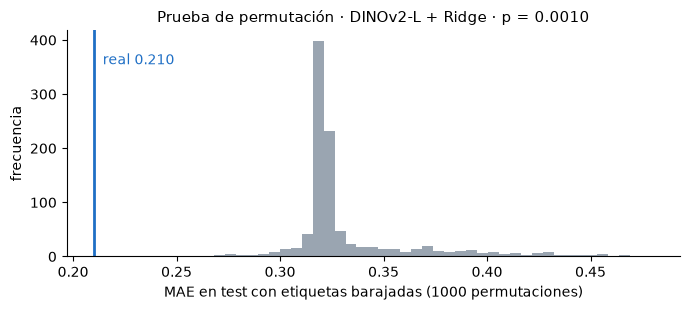

In [8]:
# Prueba de permutación: re-entrena Ridge (misma receta: estandarizar + Ridge ponderado por sesión, alpha elegido en val)
# con etiquetas barajadas entre sesiones de train y de val. Test conserva sus etiquetas reales.
z = np.load(RAIZ / 'cache' / 'dinov2_l_mascara_clahe_cls_parches_448.npz', allow_pickle=True)
X = pd.DataFrame(z['X'], index=z['archivo']).loc[p['archivo_limpio']].to_numpy()
tr, va, tst = (np.where(p['split'] == s)[0] for s in ['train', 'val', 'test'])
w = (1 / p.groupby('id_vaca')['bcs'].transform('size')).to_numpy()
ALPHAS = np.logspace(-1, 5, 25)

mu, sd = X[tr].mean(0), X[tr].std(0); sd[sd == 0] = 1
Xs = (X - mu) / sd
wt = w[tr]; xm = (wt[:, None] * Xs[tr]).sum(0) / wt.sum()
U, s, Vt = np.linalg.svd(np.sqrt(wt)[:, None] * (Xs[tr] - xm), full_matrices=False)
def predecir(y_tr, alpha, idx):   # Ridge ponderado exacto vía SVD (mismo resultado que sklearn)
    ym = (wt * y_tr).sum() / wt.sum()
    coef = Vt.T @ ((s / (s ** 2 + alpha)) * (U.T @ (np.sqrt(wt) * (y_tr - ym))))
    return (Xs[idx] - xm) @ coef + ym
def ajustar_y_test(y):
    errs = [np.sum(w[va] * np.abs(predecir(y[tr], a, va) - y[va])) / w[va].sum() for a in ALPHAS]
    return np.abs(predecir(y[tr], ALPHAS[int(np.argmin(errs))], tst) - p['bcs'].to_numpy()[tst]).mean()

y = p['bcs'].to_numpy().copy()
real = ajustar_y_test(y)
assert abs(real - np.abs(te[PRINCIPAL] - te['bcs']).mean()) < 1e-3, 'la réplica no coincide con el modelo guardado'
rng = np.random.default_rng(SEMILLA); NPERM = 1000; perm = []
ses = p['id_vaca'].to_numpy()
for _ in range(NPERM):
    yp = y.copy()
    for idx in (tr, va):   # baraja la etiqueta de cada sesión entre sesiones de la misma partición
        u = pd.unique(ses[idx]); lab = p.iloc[idx].groupby('id_vaca')['bcs'].first().loc[u].to_numpy()
        mapa = dict(zip(u, rng.permutation(lab))); yp[idx] = [mapa[k] for k in ses[idx]]
    perm.append(ajustar_y_test(yp))
perm = np.array(perm); pval = (1 + np.sum(perm <= real)) / (NPERM + 1)
print(f'MAE test real {real:.3f} · permutado: media {perm.mean():.3f} (P5 {np.percentile(perm, 5):.3f}) · p = {pval:.4f}')

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(perm, bins=40, color='#9aa5b1'); ax.axvline(real, color='#1f6fc5', lw=2)
ax.text(real + 0.004, ax.get_ylim()[1] * 0.85, f'real {real:.3f}', color='#1f6fc5')
ax.set_xlabel('MAE en test con etiquetas barajadas (1000 permutaciones)'); ax.set_ylabel('frecuencia')
ax.spines[['top', 'right']].set_visible(False); ax.set_title(f'Prueba de permutación · DINOv2-L + Ridge · p = {pval:.4f}', fontsize=11)
plt.tight_layout(); plt.savefig(FIG / 'fig2_permutacion.png', dpi=200); plt.show()
pd.DataFrame({'mae_real': [real], 'mae_perm_media': [perm.mean()], 'p': [pval], 'n_perm': [NPERM]}).to_csv(RAIZ / 'eval' / 'permutacion.csv', index=False)

## 5. Diagnósticos del modelo

### 5.1 Predicho contra real y sesgo por clase

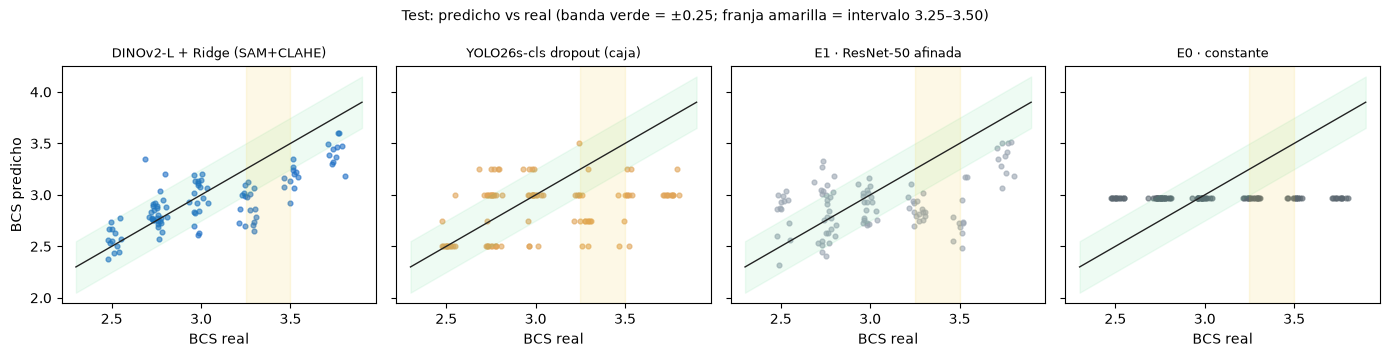

In [9]:
diag = [PRINCIPAL, 'YOLO_caja_sin_ext_dropout_top1', 'E1_cnn_afinada', 'E0_constante']
fig, axs = plt.subplots(1, 4, figsize=(14, 3.6), sharex=True, sharey=True)
jit = np.random.default_rng(0).normal(0, 0.03, len(te))
for ax, c in zip(axs, diag):
    ax.scatter(te['bcs'] + jit, te[c], s=12, alpha=0.6, color=COLOR[c])
    ax.plot([2.3, 3.9], [2.3, 3.9], color='#222', lw=1)
    ax.fill_between([2.3, 3.9], [2.05, 3.65], [2.55, 4.15], color='#2ecc71', alpha=0.08)
    ax.axvspan(*RANGO, color='#f1c40f', alpha=0.10)
    ax.set_title(MODELOS[c], fontsize=9); ax.set_xlabel('BCS real')
axs[0].set_ylabel('BCS predicho')
plt.suptitle('Test: predicho vs real (banda verde = ±0.25; franja amarilla = intervalo 3.25–3.50)', fontsize=10)
plt.tight_layout(); plt.savefig(FIG / 'fig3_predicho_vs_real.png', dpi=200); plt.show()

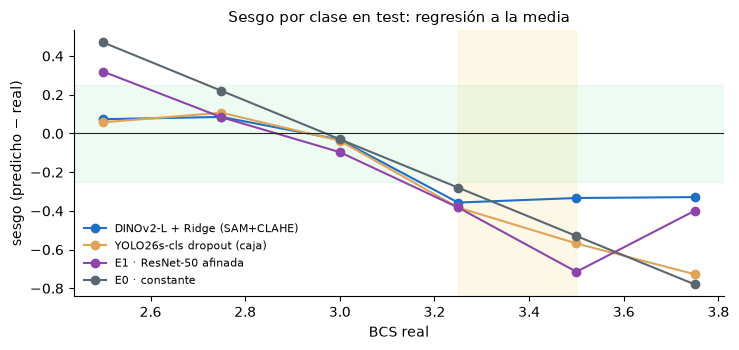

,modelo,BCS,fotos,animales,predicho medio,sesgo,MAE
0,DINOv2-L + Ridge (SAM+CLAHE),2.50,13,2,2.574,0.074,0.111
1,DINOv2-L + Ridge (SAM+CLAHE),2.75,28,5,2.836,0.086,0.116
2,DINOv2-L + Ridge (SAM+CLAHE),3.00,20,5,2.968,-0.032,0.150
3,DINOv2-L + Ridge (SAM+CLAHE),3.25,17,3,2.893,-0.357,0.357
4,DINOv2-L + Ridge (SAM+CLAHE),3.50,11,2,3.167,-0.333,0.333
5,DINOv2-L + Ridge (SAM+CLAHE),3.75,11,2,3.421,-0.329,0.329


In [10]:
# sesgo y MAE por clase de BCS real (test, por foto)
filas = []
for c in [PRINCIPAL, 'YOLO_caja_sin_ext_dropout_top1', 'E1_cnn_afinada', 'E0_constante']:
    for b, g in te.groupby('bcs'):
        filas.append({'modelo': MODELOS[c], 'BCS': b, 'fotos': len(g), 'animales': g['animal'].nunique(),
                      'predicho medio': g[c].mean(), 'sesgo': (g[c] - g['bcs']).mean(), 'MAE': (g[c] - g['bcs']).abs().mean()})
porclase = pd.DataFrame(filas); porclase.to_csv(RAIZ / 'eval' / 'por_clase_test.csv', index=False)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for c in [PRINCIPAL, 'YOLO_caja_sin_ext_dropout_top1', 'E1_cnn_afinada', 'E0_constante']:
    g = porclase[porclase['modelo'] == MODELOS[c]]
    ax.plot(g['BCS'], g['sesgo'], marker='o', color=COLOR[c] if c != 'E1_cnn_afinada' else '#8e44ad', label=MODELOS[c])
ax.axhline(0, color='#222', lw=0.8); ax.axhspan(-0.25, 0.25, color='#2ecc71', alpha=0.08); ax.axvspan(*RANGO, color='#f1c40f', alpha=0.10)
ax.set_xlabel('BCS real'); ax.set_ylabel('sesgo (predicho − real)'); ax.legend(fontsize=8, frameon=False)
ax.spines[['top', 'right']].set_visible(False); ax.set_title('Sesgo por clase en test: regresión a la media', fontsize=11)
plt.tight_layout(); plt.savefig(FIG / 'fig4_sesgo_por_clase.png', dpi=200); plt.show()
porclase[porclase['modelo'] == MODELOS[PRINCIPAL]].round(3)

### 5.2 Concordancia con el experto: Bland–Altman y matriz de confusión

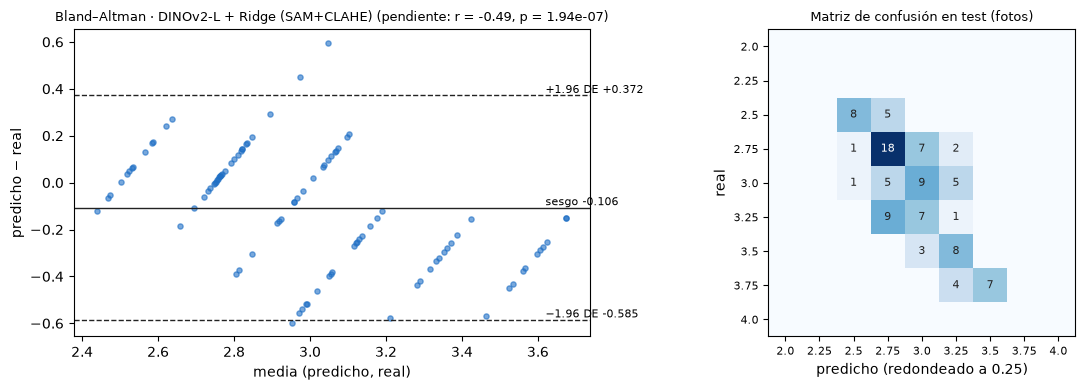

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
c = PRINCIPAL; m_ = (te[c] + te['bcs']) / 2; d_ = te[c] - te['bcs']
sesgo, lim = d_.mean(), 1.96 * d_.std(ddof=1)
axs[0].scatter(m_, d_, s=14, alpha=0.6, color=COLOR[c])
for v, t in [(sesgo, f'sesgo {sesgo:+.3f}'), (sesgo + lim, f'+1.96 DE {sesgo + lim:+.3f}'), (sesgo - lim, f'−1.96 DE {sesgo - lim:+.3f}')]:
    axs[0].axhline(v, color='#222', ls='--' if v != sesgo else '-', lw=1); axs[0].text(3.62, v + 0.01, t, fontsize=8)
r_ = stats.pearsonr(m_, d_)
axs[0].set_xlabel('media (predicho, real)'); axs[0].set_ylabel('predicho − real')
axs[0].set_title(f'Bland–Altman · {MODELOS[c]} (pendiente: r = {r_.statistic:.2f}, p = {r_.pvalue:.3g})', fontsize=9)

clases = np.arange(2.0, 4.01, 0.25)
cm = pd.crosstab(pd.Categorical(te['bcs'], clases), pd.Categorical(redondear(te[c]), clases), dropna=False)
axs[1].imshow(cm.to_numpy(), cmap='Blues')
for i in range(len(clases)):
    for j in range(len(clases)):
        v = cm.to_numpy()[i, j]
        if v: axs[1].text(j, i, v, ha='center', va='center', fontsize=8, color='white' if v > cm.to_numpy().max() / 2 else '#222')
axs[1].set_xticks(range(len(clases))); axs[1].set_xticklabels(clases, fontsize=8); axs[1].set_yticks(range(len(clases))); axs[1].set_yticklabels(clases, fontsize=8)
axs[1].set_xlabel('predicho (redondeado a 0.25)'); axs[1].set_ylabel('real'); axs[1].set_title('Matriz de confusión en test (fotos)', fontsize=9)
plt.tight_layout(); plt.savefig(FIG / 'fig5_bland_altman_confusion.png', dpi=200); plt.show()

### 5.3 Sobreajuste: MAE en train, val y test

Si la diferencia entre train y test es grande, el modelo está memorizando; si es pequeña pero el MAE es alto, el modelo no está aprendiendo.

In [12]:
filas = []
for c, n in MODELOS.items():
    fila = {'modelo': n}
    for s_ in ['train', 'val', 'test']:
        g = p[p['split'] == s_]; fila[s_] = (g[c] - g['bcs']).abs().mean()
    fila['brecha test − train'] = fila['test'] - fila['train']; filas.append(fila)
gap = pd.DataFrame(filas).sort_values('test').reset_index(drop=True); gap.to_csv(RAIZ / 'eval' / 'sobreajuste.csv', index=False)
gap.round(3)

,modelo,train,val,test,brecha test − train
0,DINOv2-L + Ridge (SAM+CLAHE),0.131,0.228,0.210,0.080
1,DINOv2-L + Ridge (caja),0.114,0.227,0.227,0.113
2,DINOv2-L + MLP,0.223,0.272,0.282,0.059
3,ResNet-50 + Ridge,0.048,0.243,0.293,0.246
4,E0 · constante,0.328,0.342,0.320,-0.008
5,YOLO26s-cls base (SAM),0.034,0.244,0.325,0.290
6,E1 · ResNet-50 afinada,0.178,0.257,0.325,0.147
7,YOLO26s-cls dropout (caja),0.006,0.282,0.328,0.322
8,YOLO26s-cls base (caja),0.002,0.304,0.360,0.358


## 6. Validación cruzada de 5 folds (solo validación)

Usamos los mismos modelos con los 5 folds por animal (semilla 42). En cada fold, val es un 20 % de los animales restantes y elige hiperparámetros igual que en el benchmark (protocolo C). Esto sirve para ver si el resultado del benchmark se mantiene con otros animales en test y cuánto varía.

In [13]:
F = RAIZ / 'folds'
part = pd.read_csv(F / 'particiones.csv')
part['fold'] = part[[f'fold{k}' for k in range(1, 6)]].eq('test').to_numpy().argmax(1) + 1
fo = p[['archivo_limpio', 'id_vaca', 'animal', 'bcs']].merge(part[['archivo_limpio', 'fold']], on='archivo_limpio')
for c in MODELOS:
    q = pd.read_csv(F / f'pred_{EN_FOLDS.get(c, c)}.csv'); fo = fo.merge(q.rename(columns={q.columns[1]: c}), on='archivo_limpio')
assert len(fo) == 604 and fo.groupby('animal')['fold'].nunique().max() == 1

fv = por_vaca(fo, list(MODELOS))
filas = []
for c, n in MODELOS.items():
    mf, mv = metricas(fo['bcs'], fo[c]), metricas(fv['bcs'], fv[c])
    pf = [np.abs(g[c] - g['bcs']).mean() for _, g in fo.groupby('fold')]
    filas.append({'modelo': n, 'MAE': mf['MAE'], 'RMSE': mf['RMSE'], '±0.25 %': mf['tol'], 'MAE vaca': mv['MAE'], '±0.25 % vaca': mv['tol'],
                  **{f'f{k + 1}': v for k, v in enumerate(pf)}, 'DE folds': np.std(pf, ddof=1)})
cv = pd.DataFrame(filas).sort_values('MAE').reset_index(drop=True); cv.to_csv(RAIZ / 'eval' / 'folds.csv', index=False)
cv.round(3)

,modelo,MAE,RMSE,±0.25 %,MAE vaca,±0.25 % vaca,f1,f2,f3,f4,f5,DE folds
0,DINOv2-L + MLP,0.277,0.349,70.530,0.246,76.344,0.283,0.232,0.323,0.238,0.315,0.042
1,DINOv2-L + Ridge (SAM+CLAHE),0.283,0.366,70.033,0.240,75.269,0.298,0.274,0.289,0.283,0.266,0.012
2,YOLO26s-cls base (SAM),0.289,0.360,68.212,0.250,74.194,0.275,0.319,0.324,0.270,0.264,0.029
3,DINOv2-L + Ridge (caja),0.293,0.381,73.179,0.255,77.419,0.362,0.246,0.343,0.251,0.242,0.059
4,ResNet-50 + Ridge,0.312,0.386,65.563,0.288,72.043,0.357,0.265,0.314,0.292,0.318,0.034
5,E1 · ResNet-50 afinada,0.313,0.386,65.066,0.297,67.742,0.311,0.271,0.385,0.320,0.271,0.047
6,E0 · constante,0.334,0.408,61.424,0.324,61.290,0.318,0.241,0.387,0.324,0.408,0.066
7,YOLO26s-cls base (caja),0.366,0.465,57.285,0.327,61.290,0.316,0.376,0.424,0.339,0.398,0.044
8,YOLO26s-cls dropout (caja),0.381,0.479,52.815,0.324,63.441,0.368,0.392,0.422,0.330,0.410,0.037


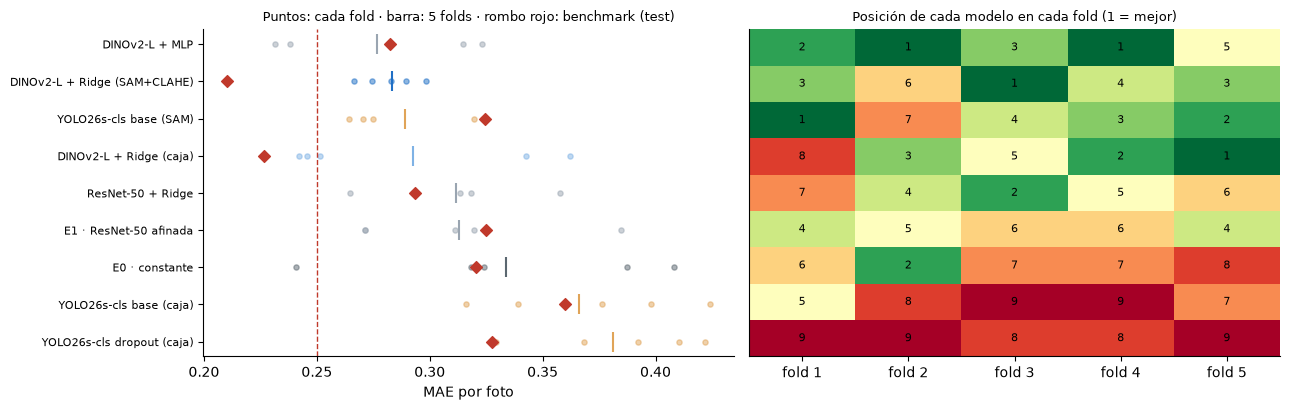

In [14]:
# Figura 6: benchmark vs validación cruzada (MAE por foto) y dispersión por fold
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
orden = cv.sort_values('MAE', ascending=False)['modelo'].tolist()
for i, n in enumerate(orden):
    c = inv[n]; f_ = cv.set_index('modelo').loc[n]
    axs[0].scatter([f_[f'f{k}'] for k in range(1, 6)], [i] * 5, s=14, color=COLOR[c], alpha=0.5)
    axs[0].scatter(f_['MAE'], i, marker='|', s=200, color=COLOR[c])
    axs[0].scatter(bench.set_index('modelo').loc[n, 'MAE'], i, marker='D', s=36, color='#c0392b', zorder=3)
axs[0].axvline(0.25, color='#c0392b', ls='--', lw=1)
axs[0].set_yticks(range(len(orden))); axs[0].set_yticklabels(orden, fontsize=8)
axs[0].set_xlabel('MAE por foto'); axs[0].set_title('Puntos: cada fold · barra: 5 folds · rombo rojo: benchmark (test)', fontsize=9)
rk = cv.set_index('modelo')[[f'f{k}' for k in range(1, 6)]].rank()
axs[1].imshow(rk.loc[orden].to_numpy(), cmap='RdYlGn_r', aspect='auto', origin='lower')
for i in range(len(orden)):
    for j in range(5): axs[1].text(j, i, int(rk.loc[orden[i]].iloc[j]), ha='center', va='center', fontsize=8)
axs[1].set_xticks(range(5)); axs[1].set_xticklabels([f'fold {k}' for k in range(1, 6)]); axs[1].set_yticks([])
axs[1].set_title('Posición de cada modelo en cada fold (1 = mejor)', fontsize=9)
for a in axs: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(FIG / 'fig6_folds.png', dpi=200); plt.show()

t de Student corregida para validación cruzada (Nadeau & Bengio, 2003). Los folds comparten datos de entrenamiento, así que la t pareada normal subestima la varianza. La corrección multiplica la varianza por (1/k + n_test/n_train).

In [15]:
def t_corregida(a, b):
    da = fo.assign(e=(fo[a] - fo['bcs']).abs()).groupby('fold')['e'].mean()
    db = fo.assign(e=(fo[b] - fo['bcs']).abs()).groupby('fold')['e'].mean()
    d = (db - da).to_numpy(); k = len(d)
    nt = fo.groupby('fold').size().to_numpy(); ratio = np.mean(nt / (len(fo) - nt))
    t = d.mean() / np.sqrt((1 / k + ratio) * d.var(ddof=1))
    return d.mean(), t, 2 * stats.t.sf(abs(t), k - 1), int((d > 0).sum())

filas = [dict(zip(['comparación', 'ΔMAE medio', 't corregida', 'p', 'folds a favor'], [f'{MODELOS[PRINCIPAL]} vs {MODELOS[c]}', *t_corregida(PRINCIPAL, c)])) for c in MODELOS if c != PRINCIPAL]
tc = pd.DataFrame(filas); tc['p Holm'] = holm(tc['p']); tc.to_csv(RAIZ / 'eval' / 't_corregida_folds.csv', index=False)
tc.round(4)

,comparación,ΔMAE medio,t corregida,p,folds a favor,p Holm
0,DINOv2-L + Ridge (SAM+CLAHE) vs E0 · constante,0.0536,1.1695,0.3072,4,1.000
1,DINOv2-L + Ridge (SAM+CLAHE) vs ResNet-50 + Ridge,0.0271,1.4016,0.2336,4,1.000
2,DINOv2-L + Ridge (SAM+CLAHE) vs E1 · ResNet-50...,0.0295,1.1039,0.3316,4,1.000
3,DINOv2-L + Ridge (SAM+CLAHE) vs YOLO26s-cls ba...,0.0884,2.6008,0.0600,5,0.420
4,DINOv2-L + Ridge (SAM+CLAHE) vs YOLO26s-cls dr...,0.1022,3.6320,0.0221,5,0.177
5,DINOv2-L + Ridge (SAM+CLAHE) vs YOLO26s-cls ba...,0.0083,0.4108,0.7023,2,1.000
6,DINOv2-L + Ridge (SAM+CLAHE) vs DINOv2-L + MLP,-0.0041,-0.1423,0.8937,2,1.000
7,DINOv2-L + Ridge (SAM+CLAHE) vs DINOv2-L + Rid...,0.0065,0.2029,0.8491,2,1.000


Con solo 5 folds la t corregida tiene poca potencia (4 grados de libertad). Por eso también aplicamos las pruebas del benchmark (bootstrap pareado y Wilcoxon por animal con Holm) sobre las predicciones fuera de fold de los 80 animales, donde cada foto la predijo un modelo que nunca vio a esa vaca.

In [16]:
po = tabla_pruebas(fo, [(PRINCIPAL, c) for c in MODELOS if c != PRINCIPAL])
po.to_csv(RAIZ / 'eval' / 'pruebas_oof.csv', index=False)
po.round(4)

,comparación,ΔMAE,IC95 bajo,IC95 alto,p Wilcoxon,p Holm,IC excluye 0
0,DINOv2-L + Ridge (SAM+CLAHE) vs E0 · constante,0.0503,0.0016,0.0988,0.0016,0.0068,True
1,DINOv2-L + Ridge (SAM+CLAHE) vs ResNet-50 + Ridge,0.0282,-0.0060,0.0632,0.0014,0.0068,False
2,DINOv2-L + Ridge (SAM+CLAHE) vs E1 · ResNet-50...,0.0293,-0.0056,0.0656,0.0006,0.0036,False
3,DINOv2-L + Ridge (SAM+CLAHE) vs YOLO26s-cls ba...,0.0824,0.0399,0.1246,0.0000,0.0003,True
4,DINOv2-L + Ridge (SAM+CLAHE) vs YOLO26s-cls dr...,0.0977,0.0509,0.1440,0.0001,0.0010,True
5,DINOv2-L + Ridge (SAM+CLAHE) vs YOLO26s-cls ba...,0.0057,-0.0246,0.0339,0.3698,0.7042,False
6,DINOv2-L + Ridge (SAM+CLAHE) vs DINOv2-L + MLP,-0.0067,-0.0275,0.0149,0.1808,0.5425,False
7,DINOv2-L + Ridge (SAM+CLAHE) vs DINOv2-L + Rid...,0.0093,-0.0222,0.0402,0.3521,0.7042,False


In [17]:
# Control con etiquetas barajadas en folds (mismo pipeline DINOv2-L + Ridge)
q = pd.read_csv(F / 'pred_control_barajado_dinov2_l_448.csv').merge(fo[['archivo_limpio', 'bcs', 'E0_constante']], on='archivo_limpio')
print(f"MAE control barajado {np.abs(q.iloc[:, 1] - q['bcs']).mean():.3f} · E0 {np.abs(q['E0_constante'] - q['bcs']).mean():.3f} · DINOv2-L + Ridge {np.abs(fo[PRINCIPAL] - fo['bcs']).mean():.3f}")

MAE control barajado 0.336 · E0 0.334 · DINOv2-L + Ridge 0.283


### 6.1 Robustez a la asignación de folds (6 semillas)

Corremos DINOv2-L + Ridge (SAM+CLAHE) con 6 asignaciones distintas de animales a folds, eligiendo alpha por validación cruzada interna por animal (protocolo A). Evaluamos los criterios en el rango completo y en el intervalo original.

In [18]:
E = RAIZ / 'exp'; col = 'dinov2_l_mascara_clahe_cls_parches_448'
archivos = {42: E / 'pred_ridge_f42.csv', **{k: E / f'pred_ridge_f{k}_{col}.csv' for k in range(1, 6)}}
filas = []
for sem, f in archivos.items():
    d = pd.read_csv(f, dtype={'id_vaca': str, 'animal': str}); v = por_vaca(d, [col])
    for nivel, df in [('foto', d), ('vaca', v)]:
        for nombre, sub in [('rango completo', df), ('3.25–3.50', df[df['bcs'].between(*RANGO)])]:
            m = metricas(sub['bcs'], sub[col])
            filas.append({'semilla': sem, 'nivel': nivel, 'criterio': nombre, 'n': m['n'], 'MAE': m['MAE'], 'RMSE': m['RMSE'], '±0.25 %': m['tol'], 'cumple': cumple(m)})
sem = pd.DataFrame(filas); sem.to_csv(RAIZ / 'eval' / 'semillas.csv', index=False)
res = sem.groupby(['criterio', 'nivel']).agg(MAE=('MAE', 'mean'), RMSE=('RMSE', 'mean'), tol=('±0.25 %', 'mean'), MAE_min=('MAE', 'min'), MAE_max=('MAE', 'max'), semillas_que_cumplen=('cumple', 'sum'))
res['cumple en promedio'] = (res['MAE'] <= 0.25) & (res['RMSE'] <= 0.35) & (res['tol'] >= 80)
res.round(3)

MAE   RMSE     tol  MAE_min  MAE_max  semillas_que_cumplen  cumple en promedio
criterio       nivel                                                                                  
3.25–3.50      foto   0.237  0.290  80.606    0.189    0.263                     4                True
               vaca   0.212  0.269  84.524    0.185    0.227                     5                True
rango completo foto   0.243  0.318  79.029    0.228    0.261                     3               False
               vaca   0.211  0.287  83.333    0.202    0.224                     5                True

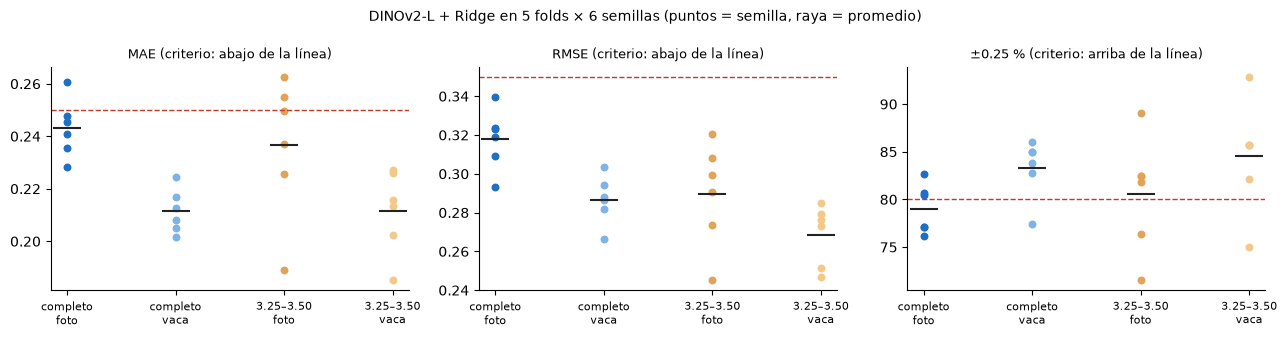

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (met, lim, mejor) in zip(axs, [('MAE', 0.25, 'abajo'), ('RMSE', 0.35, 'abajo'), ('±0.25 %', 80, 'arriba')]):
    for k, (crit_, nivel) in enumerate([('rango completo', 'foto'), ('rango completo', 'vaca'), ('3.25–3.50', 'foto'), ('3.25–3.50', 'vaca')]):
        g = sem[(sem['criterio'] == crit_) & (sem['nivel'] == nivel)]
        ax.scatter([k] * len(g), g[met], color=['#1f6fc5', '#7fb2e5', '#e0a458', '#f3c98b'][k], s=22)
        ax.scatter(k, g[met].mean(), marker='_', s=400, color='#222')
    ax.axhline(lim, color='#c0392b', ls='--', lw=1)
    ax.set_xticks(range(4)); ax.set_xticklabels(['completo\nfoto', 'completo\nvaca', '3.25–3.50\nfoto', '3.25–3.50\nvaca'], fontsize=8)
    ax.set_title(f'{met} (criterio: {mejor} de la línea)', fontsize=9); ax.spines[['top', 'right']].set_visible(False)
plt.suptitle('DINOv2-L + Ridge en 5 folds × 6 semillas (puntos = semilla, raya = promedio)', fontsize=10)
plt.tight_layout(); plt.savefig(FIG / 'fig7_semillas.png', dpi=200); plt.show()

## 7. Ablación: variantes de DINOv2

Aquí vemos qué parte del pipeline aporta: tamaño del modelo (B contra L), resolución (224 contra 448), representación (solo CLS contra CLS más el promedio de parches), recorte (SAM contra SAM+CLAHE) y cabeza (Ridge contra MLP). Se reporta el MAE por foto en el benchmark y en los 5 folds.

In [20]:
hp = pd.read_csv(H / 'pred_holdout.csv'); hp = hp[hp['split'] == 'test']
filas = []
for c in [c for c in hp.columns if c.startswith(('ridge_dinov2', 'E4_mlp_dinov2', 'ridge_resnet'))]:
    partes = c.replace('E4_mlp_', 'mlp_').split('_')
    ff = F / f"pred_{c.replace('E4_mlp_', 'mlp_')}.csv"
    q = pd.read_csv(ff).merge(fo[['archivo_limpio', 'bcs']], on='archivo_limpio') if ff.exists() else None
    filas.append({'cabeza': 'MLP' if c.startswith('E4') else 'Ridge', 'red': partes[1] + ('-' + partes[2].upper() if partes[1] == 'dinov2' else ''),
                  'recorte': 'SAM+CLAHE' if 'clahe' in c else 'SAM', 'representación': 'CLS+parches' if 'parches' in c else ('CLS' if 'cls' in c else 'final'),
                  'resolución': int(partes[-1]), 'MAE test': (hp[c] - hp['bcs']).abs().mean(),
                  'MAE 5 folds': (q.iloc[:, 1] - q['bcs']).abs().mean() if q is not None else np.nan})
abl = pd.DataFrame(filas).sort_values('MAE test').reset_index(drop=True); abl.to_csv(RAIZ / 'eval' / 'ablacion.csv', index=False)
abl.round(3)

,cabeza,red,recorte,representación,resolución,MAE test,MAE 5 folds
0,Ridge,dinov2-L,SAM+CLAHE,CLS+parches,448,0.210,0.283
1,Ridge,dinov2-L,SAM,CLS+parches,448,0.220,0.278
2,Ridge,dinov2-L,SAM+CLAHE,CLS,224,0.231,0.298
3,Ridge,dinov2-L,SAM+CLAHE,CLS,448,0.234,0.292
4,Ridge,dinov2-L,SAM,CLS,448,0.235,0.283
5,MLP,dinov2-L,SAM+CLAHE,CLS,448,0.242,0.305
6,Ridge,dinov2-L,SAM+CLAHE,CLS+parches,224,0.246,0.286
7,Ridge,dinov2-L,SAM,CLS,224,0.251,0.304
8,Ridge,dinov2-B,SAM,CLS+parches,448,0.256,0.296
9,Ridge,dinov2-B,SAM,CLS,448,0.271,0.305


In [21]:
# efecto promedio de cada decisión (solo Ridge sobre DINOv2)
a = abl[(abl['cabeza'] == 'Ridge') & abl['red'].str.startswith('dinov2')]
efectos = pd.DataFrame([
    {'decisión': 'L en vez de B', 'Δ MAE test': a[a.red == 'dinov2-L']['MAE test'].mean() - a[a.red == 'dinov2-B']['MAE test'].mean()},
    {'decisión': '448 en vez de 224', 'Δ MAE test': a[a['resolución'] == 448]['MAE test'].mean() - a[a['resolución'] == 224]['MAE test'].mean()},
    {'decisión': 'CLS+parches en vez de CLS', 'Δ MAE test': a[a['representación'] == 'CLS+parches']['MAE test'].mean() - a[a['representación'] == 'CLS']['MAE test'].mean()},
    {'decisión': 'SAM+CLAHE en vez de SAM', 'Δ MAE test': a[a.recorte == 'SAM+CLAHE']['MAE test'].mean() - a[a.recorte == 'SAM']['MAE test'].mean()},
])
efectos.round(3)   # negativo = la decisión reduce el error

,decisión,Δ MAE test
0,L en vez de B,-0.053
1,448 en vez de 224,-0.028
2,CLS+parches en vez de CLS,-0.003
3,SAM+CLAHE en vez de SAM,-0.000


## 8. Resumen

Las tablas de esta libreta se guardan en `~/bcs_data/eval/` (fuera del repositorio) y las figuras en `~/bcs_data/eval/figs/`. El reporte de Evaluation se armó a partir de ellas y la interpretación completa está en `docs/6_evaluation/`.

In [22]:
r = bench.set_index('modelo')
print('Benchmark (test, por foto):')
for n in [MODELOS[PRINCIPAL], MODELOS['E0_constante']]:
    print(f"  {n:32s} MAE {r.loc[n, 'MAE']:.3f} · RMSE {r.loc[n, 'RMSE']:.3f} · ±0.25 {r.loc[n, '±0.25 %']:.0f} % · κw {r.loc[n, 'κ_w']:.2f}")
print(f"Prueba de permutación: p = {pval:.4f}")
print('Criterio original 3.25–3.50 (test, foto):', crit.query("modelo == @MODELOS[@PRINCIPAL] and nivel == 'foto' and criterio == 'original 3.25–3.50'")[['MAE', 'RMSE', '±0.25 %', 'cumple']].round(3).to_dict('records'))
print('Criterio ajustado, rango completo (test, foto):', crit.query("modelo == @MODELOS[@PRINCIPAL] and nivel == 'foto' and criterio == 'ajustado: rango completo'")[['MAE', 'RMSE', '±0.25 %', 'cumple']].round(3).to_dict('records'))

Benchmark (test, por foto):
  DINOv2-L + Ridge (SAM+CLAHE)     MAE 0.210 · RMSE 0.265 · ±0.25 81 % · κw 0.68
  E0 · constante                   MAE 0.320 · RMSE 0.392 · ±0.25 65 % · κw 0.00
Prueba de permutación: p = 0.0010
Criterio original 3.25–3.50 (test, foto): [{'MAE': 0.348, 'RMSE': 0.374, '±0.25 %': 57.143, 'cumple': False}]
Criterio ajustado, rango completo (test, foto): [{'MAE': 0.21, 'RMSE': 0.265, '±0.25 %': 81.0, 'cumple': True}]
